# `roselab_responsiveness`: a user guide with one animal

This notebook shows how to answer the everyday questions with the responsiveness tables, step by step, on real data:
one mouse (**ROS-1881**), one recording day, one cell. Each section introduces a table, says what each of its columns
means, and shows the query that answers the question.

| question | table | section |
|---|---|---|
| which recordings of my animal are in the schema, and with which traces and windows? | `ResponseTask`, `Readout` | 1–2 |
| is the recording and the cell trustworthy? | `ScanQuality`, `Quality`, `TraceQuality` | 3 |
| which stimuli, when, and when were they really on screen? | `EventSet`, `ScreenTiming` | 4 |
| how is a response measured? | `ReadoutParamSet` | 5 |
| which cells respond, reliably? | `CellRule` + `cells()` | 6 |
| everything about one cell | all of them | 7 |
| what does the response look like? | traces + `EventSet.Onset` + `Readout` windows | 8 |
| single trials and conditions | `Readout.Cell.trial_resp`, `Readout.Condition` | 9 |
| the measures, side by side | `Readout.Cell`, `Zeta.Cell` | 10 |
| natural images | read-out 11 / ZETA | 11 |
| receptive fields from the checkerboard | `Readout.Condition` with x\|y labels | 12 |
| the same across all sessions of the animal | `cells()` with a subject restriction | 13 |
| are the tests honest? | random-onset controls | 14 |
| copy-paste recipes | | 15 |

Orientation and direction tuning (`DirectionTuning`) has its own in-depth notebook:
`notebooks/responsiveness_tuning_example.ipynb`. The design and every decision behind the tables:
`docs/RESPONSIVENESS_SCHEMA_PROPOSAL.md`.

**In your own code** you activate the module once and use it like any DataJoint schema:

```python
from adamacs.workers import responsiveness_worker as w
resp, imaging = w.activate("roselab_responsiveness")
good = resp.cells("gratings_cascade25", {"event_selector": "gratings"}) & "is_responsive AND is_reliable"
```

Activation writes the lookup tables' contents (idempotently). This notebook must stay read-only, so it uses virtual
modules instead and binds the module's own `cells()` to them: the queries are exactly the production ones.

In [1]:
import os, sys, types, logging, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
import datajoint as dj
dj.logger.setLevel(logging.WARNING)                                   # after the import: keeps the server address out of the outputs
from IPython.display import display, Markdown

for _c in ("../dj_local_conf.json", "dj_local_conf.json", os.path.expanduser("~/adamacs/dj_local_conf.json")):
    if os.path.exists(_c):
        dj.config.load(_c); break
dj.config["database.use_tls"] = False
dj.config["display.limit"] = 8
dj.conn().query("SET SESSION transaction_read_only = 1")                 # read-only, enforced by the server
assert dj.conn().query("SELECT @@transaction_read_only").fetchone()[0] == 1
vm = lambda db: dj.create_virtual_module(db, db, create_schema=False, create_tables=False)
r, imaging, session, scan, event = (vm("roselab_responsiveness"), vm("roselab_imaging"), vm("roselab_session"),
                                    vm("roselab_scan"), vm("roselab_event"))

sys.path.insert(0, "..")
import adamacs.schemas.responsiveness as R                              # importing does not touch the database
from adamacs.responsiveness import tuning as T
# the production cells() bound to the virtual modules (same code, read-only)
cells = types.FunctionType(R.cells.__code__, {**R.__dict__, "CellRule": r.CellRule, "Quality": r.Quality,
                           "TraceQuality": r.TraceQuality, "Readout": r.Readout, "Zeta": r.Zeta,
                           "_up": lambda name: {"imaging": imaging}[name]}, "cells")

mpl.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
COL = {"cascade25": "#e76f51", "oasis": "#2a9d8f", "dff0_r2": "#2b2d42"}
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 200)

def columns(table, only=None):
    # the column comments stored in the database: what each value means
    h = table.heading
    names = only or h.secondary_attributes
    return pd.DataFrame({"column": names, "meaning": [h.attributes[a].comment for a in names]}).set_index("column")

SUBJECT = "ROS-1881"

## 1. Which recordings of the animal are in the schema?

`ResponseTask` lists what the worker was asked to compute: one row per recording (session, scan, the curation's
`paramset_idx` / `curation_id`), trace type (`trace_source`) and stimulus set (`event_selector`). The `*_random`
selectors are the no-stimulus controls (section 14). Each recording here is its own session; a recording day has one
grating, one natural-image and one checkerboard recording.

In [2]:
sess = session.Session & {"subject": SUBJECT}
tasks = pd.DataFrame((r.ResponseTask * sess.proj("session_datetime")).fetch(as_dict=True))
tasks["day"] = pd.to_datetime(tasks.session_datetime).dt.date
real = tasks[~tasks.event_selector.str.endswith("_random")]
overview = real.pivot_table(index="day", columns="event_selector", values="scan_id", aggfunc="first")
print(f"{SUBJECT}: {real.scan_id.nunique()} recordings on {overview.shape[0]} days; trace types {sorted(real.trace_source.unique())}")
display(overview.head(8))
# the first day with all three paradigms is our example day
DAY = overview.dropna(subset=["gratings", "nat_images_repeated", "rf_checkerboard"]).index[0]
G, IMG, RF = (overview.loc[DAY, s] for s in ("gratings", "nat_images_repeated", "rf_checkerboard"))
def rec(scan_id):    # the recording key: session, scan and the curation the worker used
    return (dj.U("session_id", "scan_id", "paramset_idx", "curation_id") & (r.ResponseTask & {"scan_id": scan_id})).fetch1()
GK, IK, RK = rec(G), rec(IMG), rec(RF)
print(f"example day {DAY}: gratings {G}, natural images {IMG}, checkerboard {RF}")
print("gratings recording key:", GK)

ROS-1881: 52 recordings on 25 days; trace types ['cascade25', 'dff0_r2', 'oasis']


event_selector,gratings,nat_images_repeated,rf_checkerboard
day,,,
2024-09-02,NaN,NaN,scan9FPXNI8U
2024-09-03,scan9FPY8W73,scan9FPYA6OO,scan9FPYATWH
2024-09-04,scan9FPYUH9D,NaN,NaN
2024-09-05,scan9FPZGABI,scan9FPZHKKB,NaN
2024-09-06,scan9FQ014RK,scan9FQ02HKO,scan9FQ035HU
2024-09-07,scan9FQ0MLVT,scan9FQ0NVS3,NaN
2024-09-08,scan9FQ18FWL,scan9FQ19Q01,NaN
2024-09-09,scan9FQ1TN3R,scan9FQ1UYJD,NaN


example day 2024-09-03: gratings scan9FPY8W73, natural images scan9FPYA6OO, checkerboard scan9FPYATWH
gratings recording key: {'session_id': 'sess9FPY8W73', 'scan_id': 'scan9FPY8W73', 'paramset_idx': 11, 'curation_id': 1}


## 2. What was computed for one recording

For every task the worker computes read-outs (`Readout`, one per window definition `readout_idx`), ZETA tests on some
of them (`Zeta`, `zeta_idx`) and, for moving gratings, tuning (`DirectionTuning`, `tuning_idx`). A row of `Readout`
is a whole recording × trace type × stimulus set × window; its part table `Readout.Cell` holds one row per cell.

In [3]:
ro = pd.DataFrame((r.Readout & GK).proj("n_onsets", "n_repeats", "resp_start_s", "resp_stop_s", "base_start_s", "base_stop_s").fetch(as_dict=True))
display(ro.pivot_table(index=["event_selector", "readout_idx"], columns="trace_source", values="n_onsets", aggfunc="first"))
print("Zeta:", sorted(set(map(tuple, pd.DataFrame((r.Zeta & GK).fetch("event_selector", "readout_idx", "zeta_idx", as_dict=True)).values.tolist()))))
print("DirectionTuning:", len(r.DirectionTuning & GK), "rows (trace types x tuning settings)")

trace_source                 cascade25  dff0_r2  oasis
event_selector  readout_idx                           
gratings        2                144.0    144.0  144.0
                15               144.0    144.0  144.0
                16               144.0    144.0  144.0
gratings_random 2                  NaN      NaN  144.0
                15                 NaN      NaN  144.0
                16                 NaN      NaN  144.0

Zeta: [('gratings', 16, 1), ('gratings_random', 16, 1)]
DirectionTuning: 3 rows (trace types x tuning settings)


## 3. Is the recording and the cell trustworthy?

Three tables, computed before any stimulus is looked at:

* `ScanQuality`, per recording: the detector gain (grey levels per detected photon) from shutter-closed frames
  (`gain_method = 'dark'`) or, without them, from a photon-transfer fit (`'ptc'`).
* `Quality`, per curation, and `Quality.Cell`, per ROI: kurtosis of the raw fluorescence (low = noise or neuropil),
  the correlation with its neuropil, and photons per second (needs the gain). The master row also holds the neuropil
  factor that would decorrelate the cells (`alpha_opt`; the pipeline uses 0.7).
* `TraceQuality.Cell`, per ROI and trace type: SNR, event rate, mean and maximum of the trace (CASCADE values above 50
  spikes/s are non-physical).

In [4]:
display(columns(r.ScanQuality))
display((r.ScanQuality & [{"scan_id": s} for s in (G, IMG, RF)]).proj("gain_method", "gain", "offset", "gain_r2", "n_dark_frames").fetch(format="frame"))
display(columns(r.Quality.Cell))
q = (r.Quality.Cell & GK).fetch(format="frame")
print("gratings recording, per ROI:"); display(q[["kurtosis", "neuropil_r", "photons_per_s"]].describe().T.round(2))
display(columns(r.TraceQuality.Cell))
tq = (r.TraceQuality.Cell & GK).fetch(format="frame").reset_index()
display(tq.groupby("trace_source")[["snr_s2p", "event_rate", "mean_level", "max_value"]].median().round(3))

,meaning
column,
gain_method,dark: offset + read noise from shutter-closed frames; ptc: free-intercept fit (no dark frames)
gain,"[grey levels / detected photon] (V - dark_var) = gain*(I - offset), frame-pair variance"
offset,"[grey levels] zero-photon level (mean dark frame, or fitted intercept)"
gain_r2,fit quality over the lower half of the intensity range
n_frames,raw frames used for the fit (dark frames come in addition)
n_dark_frames,"shutter-closed frames used (0: no dark frames, ptc fallback)"


,,gain_method,gain,offset,gain_r2,n_dark_frames
session_id,scan_id,,,,,
sess9FPY8W73,scan9FPY8W73,dark,1650.827736,-21.321591,0.978160,21
sess9FPYA6OO,scan9FPYA6OO,dark,1627.174731,9.273774,0.975924,21
sess9FPYATWH,scan9FPYATWH,dark,1654.880945,-30.058200,0.981412,22


,meaning
column,
kurtosis,Pearson kurtosis of raw F (normal 3); low = noise or neuropil-dominated
neuropil_r,"r(F, Fneu); high = contaminated"
photons_per_s,"enf^2*(F0 - offset)*npix/gain*fps, F0 = 30th pct of raw F, gain/offset from ScanQuality"


gratings recording, per ROI:


,count,mean,std,min,25%,50%,75%,max
kurtosis,1230.0,7.31,4.29,2.17,4.50,5.88,8.55,38.30
neuropil_r,1230.0,0.47,0.15,0.03,0.37,0.46,0.55,0.94
photons_per_s,1233.0,8857.54,11239.84,15.61,4374.24,6355.67,9407.89,159438.00


,meaning
column,
snr_s2p,Suite2p: 1 - var(diff x)/(2 var x)
noise_nu,[percent/sqrt(Hz)] CASCADE noise level (meaningful for dF/F0 only)
event_rate,[1/min] runs >= 2 frames above 3 robust SD
mean_level,mean of the trace (for spike-rate traces: mean rate)
max_value,maximum of the trace (audit rule: CASCADE cells > 50 are non-physical)


,snr_s2p,event_rate,mean_level,max_value
trace_source,,,,
cascade25,0.889,71.407,0.014,0.902
dff0_r2,0.247,21.945,0.247,1.765
oasis,0.040,NaN,8.565,1137.560


## 4. Which stimuli, and when were they on screen?

`EventSet` is one stimulus set of one recording; `EventSet.Onset` its presentations, in order (`onset_idx` indexes
every per-trial array of the read-outs) with the parsed `condition` (grating direction label, image number, x|y
position). `ScreenTiming` reads the photodiode in the corner of the monitor: when the stimulus was physically on screen
relative to the DataJoint event (about 90 ms later). Rigs got the diode in November 2025; for older recordings, like this
one, `has_diode` is 0 and the read-outs use the selector's default display latency of 100 ms
(`Readout.latency_source = 'default'`).

In [5]:
display(columns(r.EventSet))
display((r.EventSet & [GK, IK, RK]).fetch(format="frame").drop(columns=[], errors="ignore"))
on = (r.EventSet.Onset & GK & {"event_selector": "gratings"}).fetch(format="frame", order_by="onset_idx").reset_index()
print("first gratings onsets:"); display(on[["onset_idx", "event_start_time", "condition", "shift_s"]].head(6))
print("presentations per direction label:", on.condition.value_counts().sort_index().to_dict())
display((r.ScreenTiming & GK).proj("has_diode", "n_detected", "latency_s", "latency_iqr_s", "refresh_hz").fetch(format="frame"))

,meaning
column,
n_onsets,
n_conditions,
n_trials,trials (blocks / task trials) the onsets come from
n_outside_trials,matching event.Event rows in no trial (not used)
median_duration_s,"median stimulus duration used (stim_duration_s, or event end - start)"
median_ioi_s,median onset-to-onset interval


n_onsets  n_conditions  n_trials  n_outside_trials  median_duration_s  median_ioi_s
session_id   scan_id      event_selector                                                                                                 
sess9FPY8W73 scan9FPY8W73 gratings                         144            12        12                 8            3.01325       7.01636
                          gratings_random                  144             1        12                 8            3.01325       7.01636
sess9FPYA6OO scan9FPYA6OO nat_images_repeated             1000           100         1                 0            0.50147       3.54999
                          nat_images_repeated_random      1000             1         1                 0            0.50147       3.54999
sess9FPYATWH scan9FPYATWH rf_checkerboard                  696            70         8                 4            0.99963       3.00000

first gratings onsets:


,onset_idx,event_start_time,condition,shift_s
0,0,8.92530,150,0.0
1,1,15.85745,120,0.0
2,2,22.85590,270,0.0
3,3,29.86740,180,0.0
4,4,36.89120,90,0.0
5,5,43.91545,60,0.0


presentations per direction label: {'0': 12, '120': 12, '150': 12, '180': 12, '210': 12, '240': 12, '270': 12, '30': 12, '300': 12, '330': 12, '60': 12, '90': 12}


,,,has_diode,n_detected,latency_s,latency_iqr_s,refresh_hz
session_id,scan_id,event_selector,,,,,
sess9FPY8W73,scan9FPY8W73,gratings,0,0,NaN,NaN,NaN


## 5. How is a response measured? The read-outs

A read-out turns each presentation into one number per cell: the mean of the trace in a response window, optionally
minus (or tested against) a baseline window. `ReadoutParamSet` defines the windows explicitly, from the stimulus onset
or offset, in seconds or in 2P frames; rows are never edited, a new window is a new row. The standard ones:

| paradigm | read-out | window |
|---|---|---|
| gratings | **16** | stimulus on screen, raw mean; baseline 2.0–0.33 s before onset (test only) |
| natural images | **11** (CASCADE), **3** (OASIS) | the audit's windows, no baseline: ZETA decides responsiveness |
| checkerboard | **1** | stimulus on screen minus the 0.5 s before |

In [6]:
rp = r.ReadoutParamSet & [{"readout_idx": i} for i in (1, 2, 3, 11, 15, 16)]
display(rp.proj("readout_desc").fetch(format="frame"))
display(columns(r.ReadoutParamSet, ["time_ref", "window_unit", "resp_start_ref", "resp_start", "resp_stop_ref", "resp_stop",
                                    "base_start_ref", "base_start", "base_stop_ref", "base_stop", "measure", "correction", "test"]))
print("read-out 16 on this recording, median window edges relative to the DataJoint onset [s]:")
display(ro[(ro.event_selector == "gratings") & (ro.readout_idx == 16)][["trace_source", "resp_start_s", "resp_stop_s", "base_start_s", "base_stop_s"]].round(3))

,readout_desc
readout_idx,
1,"stimulus mean: response [onset, offset), baseline [onset - 0.5 s, onset); screen time"
2,"Leon export, gratings (v1-drift-audit 234/234): frames [on, on + n), n = off - on + 2 of the first trial; ..."
3,"Leon export, natural images (v1-drift-audit 84/84): frames [on + 3, on + 3 + n), n = off - on + 2 of the f..."
11,"CASCADE images (v1-drift-audit q1 consensus window, leave-one-animal-out on the oracle): frames [on - 1, o..."
15,"as 10 (stimulus on screen [on, off) vs 30 frames ending 2 frames before onset), but the per-trial value is..."
16,"gratings standard: response = stimulus on screen, frames [on, off), RAW per-trial value; baseline (test on..."


,meaning
column,
time_ref,display: event time + EventSelector.display_latency_s (the image on
window_unit,s: seconds; frames: 2P frames from the frame NEAREST each reference time
resp_start_ref,response window START = stimulus onset or offset ...
resp_start,... + this (s or frames)
resp_stop_ref,response window END (exclusive) = stimulus onset or offset ...
resp_stop,... + this (e.g. 0 = at stimulus end; -0.2 = 200 ms before)
base_start_ref,baseline window START reference (NULL: no baseline; tests against 0)
base_start,... + this
base_stop_ref,baseline window END (exclusive) reference


read-out 16 on this recording, median window edges relative to the DataJoint onset [s]:


,trace_source,resp_start_s,resp_stop_s,base_start_s,base_stop_s
2,cascade25,0.099,3.112,-1.903,-0.235
5,dff0_r2,0.099,3.112,-1.903,-0.235
8,oasis,0.099,3.112,-1.903,-0.235


## 6. Which cells respond, reliably? `CellRule` and `cells()`

Thresholds live in `CellRule`, one named row per rule; `cells(rule, restriction)` applies a rule and returns, per cell,
the flags `is_qc`, `is_active`, `is_responsive`, `is_specific`, `is_reliable` (NULL where the rule sets no threshold)
and `is_positive` (the response is above baseline). It also drops ROIs rejected by `imaging.RoiQC` (no fluorescence,
second channel). The `_pos` rules count only activated cells as responsive.

In [7]:
display(r.CellRule.proj("rule_note").fetch(format="frame"))
g = cells("gratings_cascade25", {**GK, "event_selector": "gratings"})
f = g.fetch(format="frame")
print(f"{len(f)} soma ROIs of {G} (CASCADE, gratings, read-out 16); latency source: {(r.Readout & GK & {'readout_idx': 16, 'event_selector': 'gratings', 'trace_source': 'cascade25'}).fetch1('latency_source')}")
display(pd.Series({"responsive": f.is_responsive.mean(), "reliable": f.is_reliable.mean(),
                   "responsive AND reliable": (f.is_responsive.astype(bool) & f.is_reliable.astype(bool)).mean(),
                   "activated (is_positive)": f.is_positive.astype(float).mean()}).round(3).to_frame("fraction"))

,rule_note
cell_rule,
gratings_cascade25,gratings standard: read-out 16 t-test p < 0.05 (two-sided: includes suppression); oracle >= 0.18; soma
gratings_cascade25_pos,gratings standard: read-out 16 t-test p < 0.05; oracle >= 0.18; soma; activated only
gratings_oasis,gratings standard: read-out 16 t-test p < 0.05 (two-sided: includes suppression); oracle >= 0.18; soma
gratings_oasis_pos,gratings standard: read-out 16 t-test p < 0.05; oracle >= 0.18; soma; activated only
images_cascade25,natural images (repeated set): ZETA 1 on read-out 11's epoch p < 0.05; oracle on read-out 11 >= 0.08; soma
images_cascade25_pos,natural images (repeated set): ZETA 1 on read-out 11's epoch p < 0.05; oracle on read-out 11 >= 0.08; soma...
images_oasis,natural images (repeated set): ZETA 1 on read-out 3's epoch p < 0.05; oracle on read-out 3 >= 0.08; soma
images_oasis_pos,natural images (repeated set): ZETA 1 on read-out 3's epoch p < 0.05; oracle on read-out 3 >= 0.08; soma; ...


774 soma ROIs of scan9FPY8W73 (CASCADE, gratings, read-out 16); latency source: default


,fraction
responsive,0.588
reliable,0.695
responsive AND reliable,0.473
activated (is_positive),0.615


## 7. Everything about one cell

Below, one responsive and reliable, activated cell of the grating recording, with every value the schema holds for it
(CASCADE, read-out 16; ZETA on that read-out's epoch; tuning 1). The `meaning` column is the comment stored with each
column in the database.

In [8]:
good = (g & "is_responsive AND is_reliable AND is_positive").fetch(format="frame").reset_index()
ck = (r.Readout.Cell & good[["session_id", "scan_id", "paramset_idx", "curation_id", "mask", "fluo_channel"]].to_dict("records")
      & {"trace_source": "cascade25", "event_selector": "gratings", "readout_idx": 16}).fetch(
      "KEY", order_by="oracle_r DESC", limit=max(1, len(good) // 10))[-1]      # a clearly good cell (top 10 %), not the best
CELL = {k: ck[k] for k in ("session_id", "scan_id", "paramset_idx", "curation_id", "mask", "fluo_channel")}
print("example cell:", CELL)

def cell_report(cell, trace_source="cascade25", selector="gratings", readout_idx=16, zeta_idx=1, tuning_idx=1):
    # one table with every value of one cell, its source table and the column's meaning
    rows = []
    def add(table, restr, name):
        q = table & cell & restr
        if len(q) != 1:
            return
        vals = q.fetch1()
        for a in table.heading.secondary_attributes:
            v = vals[a]
            if isinstance(v, np.ndarray):
                v = f"array {v.shape}"
            rows.append(dict(table=name, column=a, value=v, meaning=table.heading.attributes[a].comment[:90]))
    add(r.Quality.Cell, {}, "Quality.Cell")
    add(r.TraceQuality.Cell, {"trace_source": trace_source}, "TraceQuality.Cell")
    add(r.Readout.Cell, {"trace_source": trace_source, "event_selector": selector, "readout_idx": readout_idx}, f"Readout.Cell ({readout_idx})")
    add(r.Zeta.Cell, {"trace_source": trace_source, "event_selector": selector, "readout_idx": readout_idx, "zeta_idx": zeta_idx}, "Zeta.Cell")
    add(r.DirectionTuning.Cell, {"trace_source": trace_source, "event_selector": selector, "readout_idx": readout_idx, "tuning_idx": tuning_idx}, "DirectionTuning.Cell")
    return pd.DataFrame(rows)

rep = cell_report(CELL)
print(f"{len(rep)} values; Zeta.Cell rows on read-out 16: {len(r.Zeta.Cell & CELL & {'readout_idx': 16, 'trace_source': 'cascade25'})}")
with pd.option_context("display.max_rows", 200):
    display(rep)

example cell: {'session_id': 'sess9FPY8W73', 'scan_id': 'scan9FPY8W73', 'paramset_idx': 11, 'curation_id': 1, 'mask': 54, 'fluo_channel': 0}
75 values; Zeta.Cell rows on read-out 16: 1


,table,column,value,meaning
0,Quality.Cell,kurtosis,7.41253,Pearson kurtosis of raw F (normal 3); low = noise or neuropil-dominated
1,Quality.Cell,neuropil_r,0.406677,"r(F, Fneu); high = contaminated"
2,Quality.Cell,photons_per_s,11593.8,"enf^2*(F0 - offset)*npix/gain*fps, F0 = 30th pct of raw F, gain/offset from ScanQuality"
3,TraceQuality.Cell,snr_s2p,0.873103,Suite2p: 1 - var(diff x)/(2 var x)
4,TraceQuality.Cell,noise_nu,0.020017,[percent/sqrt(Hz)] CASCADE noise level (meaningful for dF/F0 only)
5,TraceQuality.Cell,event_rate,59.9536,[1/min] runs >= 2 frames above 3 robust SD
6,TraceQuality.Cell,mean_level,0.041895,mean of the trace (for spike-rate traces: mean rate)
7,TraceQuality.Cell,max_value,1.35272,maximum of the trace (audit rule: CASCADE cells > 50 are non-physical)
8,Readout.Cell (16),trial_resp,"array (144,)","float32 (EventSet.n_onsets,) corrected read-out per onset, EventSet.Onset order; NaN = out"
9,Readout.Cell (16),trial_base,"array (144,)","float32 (EventSet.n_onsets,) baseline-window value per onset, same measure (NULL: no basel"


## 8. What does the response look like?

The read-outs are computed from the stored traces. Here the CASCADE trace of the example cell, aligned to every
grating onset, one panel per direction (θ = 90 − L, the tuning convention), with the response window (yellow) and the
baseline window (grey) of read-out 16. Frame times are the 2P frame triggers of the DAQ (`event.Event`); for
multi-plane recordings one time per volume (`volume_times`).

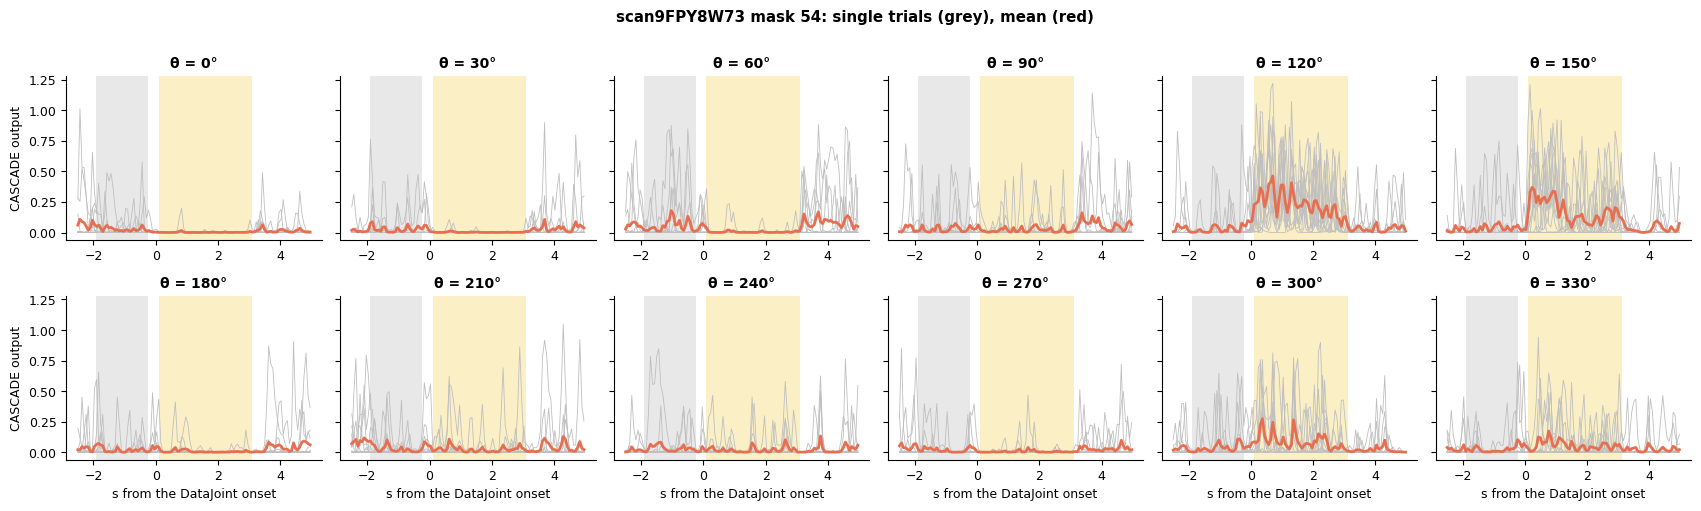

In [9]:
def frame_times(rk):
    sk = {"session_id": rk["session_id"], "scan_id": rk["scan_id"]}           # always restrict event.Event by session_id
    ft = (event.Event & sk & 'event_type LIKE "%%2p_frames%%"').fetch("event_start_time", order_by="event_start_time").astype(float)
    nd, nf = (scan.ScanInfo & sk).fetch1("ndepths", "nframes")
    return R.volume_times(ft, nd, nf)

def trace(cell, trace_source="cascade25"):
    em = (r.TraceSource & {"trace_source": trace_source}).fetch1("extraction_method")
    return (imaging.Activity.Trace & cell & {"extraction_method": em}).fetch1("activity_trace").astype(float)

ft, x = frame_times(CELL), trace(CELL)
x = x[:ft.size]; ft = ft[:x.size]
onsets = on.event_start_time.astype(float).values + on.shift_s.astype(float).values
theta = T.to_angle(on.condition.astype(float).values, "90_minus_label")
w16 = ro[(ro.event_selector == "gratings") & (ro.readout_idx == 16) & (ro.trace_source == "cascade25")].iloc[0]
pre, post = 2.5, 5.0
tgrid = np.arange(-pre, post, 1 / 15)
fig, axs = plt.subplots(2, 6, figsize=(17, 5), sharey=True)
for ax, a in zip(axs.flat, np.unique(theta)):
    segs = [np.interp(tgrid, ft - t0, x) for t0 in onsets[theta == a] if t0 - pre > ft[0] and t0 + post < ft[-1]]
    for s in segs: ax.plot(tgrid, s, color="0.75", lw=.6)
    if segs: ax.plot(tgrid, np.mean(segs, 0), color=COL["cascade25"], lw=2)
    ax.axvspan(w16.resp_start_s, w16.resp_stop_s, color="#f4d35e", alpha=.35, lw=0)
    ax.axvspan(w16.base_start_s, w16.base_stop_s, color="0.85", alpha=.6, lw=0)
    ax.set(title=f"θ = {a:g}°", xticks=[-2, 0, 2, 4])
for ax in axs[1]: ax.set_xlabel("s from the DataJoint onset")
axs[0][0].set_ylabel("CASCADE output"); axs[1][0].set_ylabel("CASCADE output")
plt.suptitle(f"{CELL['scan_id']} mask {CELL['mask']}: single trials (grey), mean (red)", y=1.01, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Single trials and conditions

`Readout.Cell.trial_resp` holds the read-out of every presentation in `EventSet.Onset` order (NaN when the window falls
outside the recording); `trial_base` the baseline window's value. `Readout.Condition` has one row per condition: mean,
SEM and the per-condition tests.

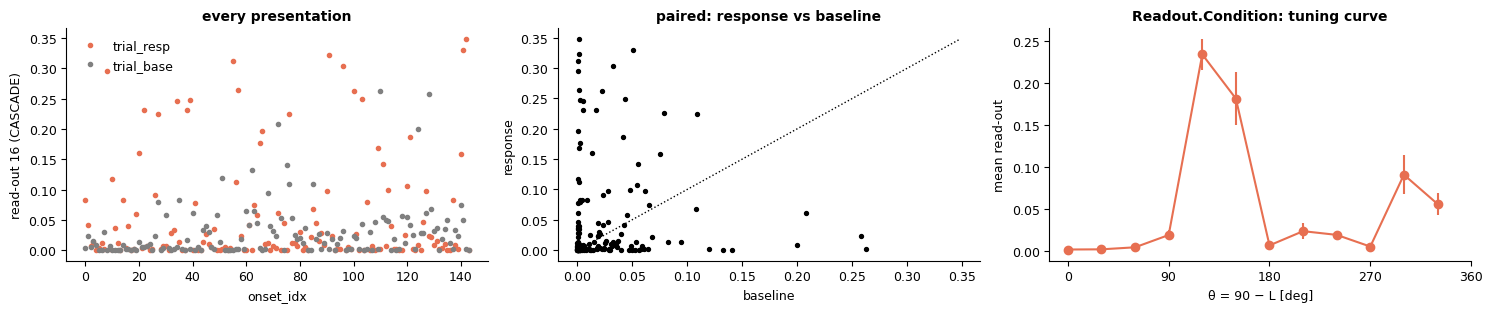

,condition,theta,n_onsets,resp,resp_sem,resp_anova_p
11,90,0.0,12,0.0020,0.0008,0.0126
10,60,30.0,12,0.0023,0.0007,0.0432
7,30,60.0,12,0.0047,0.0018,0.0611
0,0,90.0,12,0.0193,0.0063,0.4788
9,330,120.0,12,0.2345,0.0185,0.0000
8,300,150.0,12,0.1818,0.0315,0.0005
6,270,180.0,12,0.0069,0.0025,0.0541
5,240,210.0,12,0.0239,0.0096,0.8040
4,210,240.0,12,0.0195,0.0045,0.5322
3,180,270.0,12,0.0055,0.0019,0.1015


In [10]:
k16 = {**CELL, "trace_source": "cascade25", "event_selector": "gratings", "readout_idx": 16}
tr, tb = (r.Readout.Cell & k16).fetch1("trial_resp", "trial_base")
cond = (r.Readout.Condition & k16).fetch(format="frame").reset_index()
cond["theta"] = T.to_angle(cond.condition.astype(float), "90_minus_label"); cond = cond.sort_values("theta")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
ax[0].plot(tr, ".", color=COL["cascade25"], label="trial_resp"); ax[0].plot(tb, ".", color="0.5", label="trial_base")
ax[0].set(xlabel="onset_idx", ylabel="read-out 16 (CASCADE)", title="every presentation"); ax[0].legend()
ax[1].scatter(tb, tr, s=8, color="k"); m_ = np.nanmax([np.nanmax(tr), np.nanmax(tb)]); ax[1].plot([0, m_], [0, m_], "k:", lw=1)
ax[1].set(xlabel="baseline", ylabel="response", title="paired: response vs baseline")
ax[2].errorbar(cond.theta, cond.resp.astype(float), yerr=cond.resp_sem.astype(float), fmt="o-", color=COL["cascade25"])
ax[2].set(xlabel="θ = 90 − L [deg]", ylabel="mean read-out", title="Readout.Condition: tuning curve", xticks=range(0, 361, 90))
plt.tight_layout(); plt.show()
display(cond[["condition", "theta", "n_onsets", "resp", "resp_sem", "resp_anova_p"]].round(4).head(12))

## 10. The measures, side by side

All cells of the grating recording (CASCADE, read-out 16), the example cell in red. Read the columns in groups:

* **Responsive?** `resp_p` (paired t-test, response vs baseline: the standard call), `resp_anova_p` (unpaired), and
  ZETA's `zeta_p` (time-locked activity of any shape, on the read-out's whole epoch: also catches OFF responses).
* **How strong?** `resp_delta` (response − baseline; > 0 = activated), `effect_d`, and `resp_auroc` (only for equally
  long windows, so NULL on read-out 16; use read-out 2 for it).
* **Reliable?** `oracle_r` (leave-one-repeat-out correlation of the condition curve; the standard call, ≥ 0.18),
  `fev` (fraction of explainable variance), `cc_max` (the best correlation any model could reach).
* **Selective?** `cond_kw_p` (do the conditions differ?), `lifetime_sparseness` (raw read-outs only), and the tuning
  measures in `DirectionTuning`.

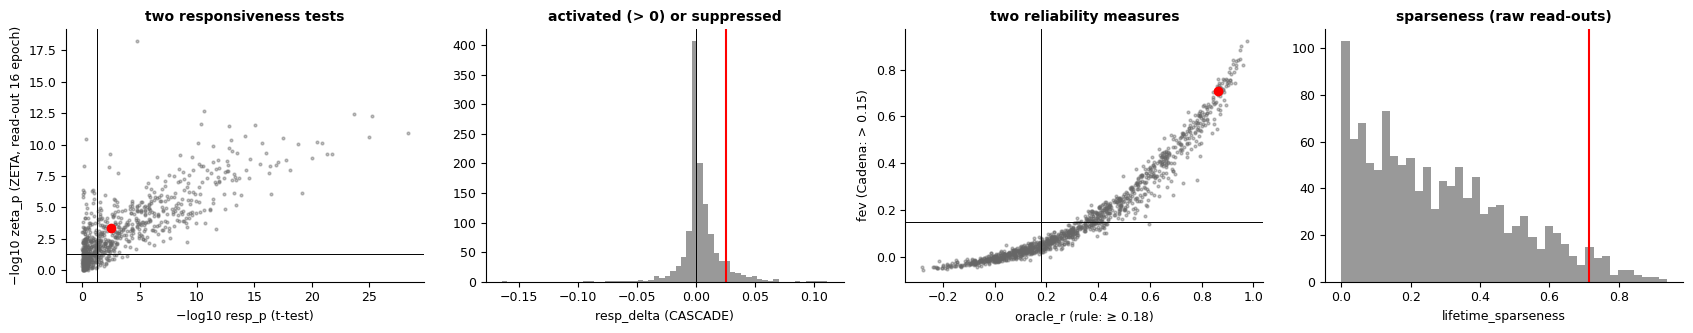

resp_p < 0.05: 55% | zeta_p < 0.05: 47% | both: 34% | oracle_r ≥ 0.18: 63% | fev > 0.15: 40%


In [11]:
cols = ["resp_p", "resp_anova_p", "resp_delta", "effect_d", "oracle_r", "fev", "cc_max", "cond_kw_p", "lifetime_sparseness"]
A = (r.Readout.Cell & GK & {"trace_source": "cascade25", "event_selector": "gratings", "readout_idx": 16}).proj(*cols).fetch(format="frame").reset_index()
Z = (r.Zeta.Cell & GK & {"trace_source": "cascade25", "event_selector": "gratings", "readout_idx": 16, "zeta_idx": 1}).proj("zeta_p").fetch(format="frame").reset_index()
A = A.merge(Z[["mask", "fluo_channel", "zeta_p"]], on=["mask", "fluo_channel"], how="left")
for c in cols + ["zeta_p"]:
    A[c] = pd.to_numeric(A[c], errors="coerce")
me = A[(A["mask"] == CELL["mask"]) & (A.fluo_channel == CELL["fluo_channel"])].iloc[0]
fig, ax = plt.subplots(1, 4, figsize=(17, 3.4))
ax[0].scatter(-np.log10(A.resp_p), -np.log10(A.zeta_p), s=4, alpha=.4, color="0.4"); ax[0].scatter(-np.log10(me.resp_p), -np.log10(me.zeta_p), color="red")
ax[0].axvline(-np.log10(.05), color="k", lw=.7); ax[0].axhline(-np.log10(.05), color="k", lw=.7)
ax[0].set(xlabel="−log10 resp_p (t-test)", ylabel="−log10 zeta_p (ZETA, read-out 16 epoch)", title="two responsiveness tests")
ax[1].hist(A.resp_delta.dropna(), bins=60, color="0.6"); ax[1].axvline(me.resp_delta, color="red"); ax[1].axvline(0, color="k", lw=.7)
ax[1].set(xlabel="resp_delta (CASCADE)", title="activated (> 0) or suppressed")
ax[2].scatter(A.oracle_r, A.fev, s=4, alpha=.4, color="0.4"); ax[2].scatter(me.oracle_r, me.fev, color="red")
ax[2].axvline(.18, color="k", lw=.7); ax[2].axhline(.15, color="k", lw=.7)
ax[2].set(xlabel="oracle_r (rule: ≥ 0.18)", ylabel="fev (Cadena: > 0.15)", title="two reliability measures")
ax[3].hist(A.lifetime_sparseness.dropna(), bins=40, color="0.6"); ax[3].set(xlabel="lifetime_sparseness", title="sparseness (raw read-outs)")
if pd.notna(me.lifetime_sparseness): ax[3].axvline(me.lifetime_sparseness, color="red")
plt.tight_layout(); plt.show()
print(f"resp_p < 0.05: {np.mean(A.resp_p < .05):.0%} | zeta_p < 0.05: {np.mean(A.zeta_p < .05):.0%} | both: {np.mean((A.resp_p < .05) & (A.zeta_p < .05)):.0%} "
      f"| oracle_r ≥ 0.18: {np.mean(A.oracle_r >= .18):.0%} | fev > 0.15: {np.mean(A.fev > .15):.0%}")

## 11. Natural images

The repeated natural-image set (`nat_images_repeated`) has no clean baseline: the gap between images still holds the
previous image's response. Responsiveness is therefore ZETA on the read-out's epoch (`images_cascade25` rule: ZETA 1 on
read-out 11, oracle ≥ 0.08), and the sign comes from `resp_vs_trace` (response above the cell's mean activity).

scan9FPYA6OO: 772 soma ROIs | ZETA-responsive 63% | reliable (oracle ≥ 0.08) 51% | both 46%


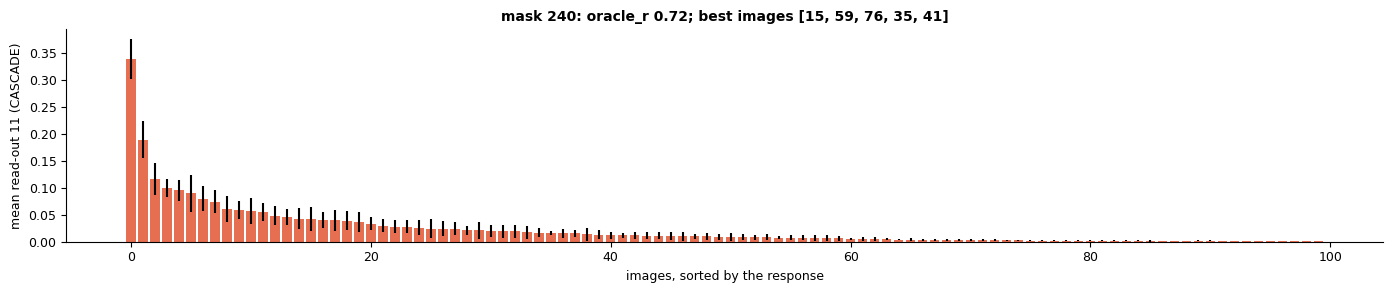

In [12]:
gi = cells("images_cascade25", {**IK, "event_selector": "nat_images_repeated"})
fi = gi.fetch(format="frame")
print(f"{IMG}: {len(fi)} soma ROIs | ZETA-responsive {fi.is_responsive.mean():.0%} | reliable (oracle ≥ 0.08) {fi.is_reliable.mean():.0%} | both {(fi.is_responsive.astype(bool) & fi.is_reliable.astype(bool)).mean():.0%}")
best = (r.Readout.Cell & (gi & "is_responsive AND is_reliable").proj() & {"readout_idx": 11, "trace_source": "cascade25"}).fetch(
       "KEY", "oracle_r", order_by="oracle_r DESC", limit=1, as_dict=True)
if best:
    kk = {k: v for k, v in best[0].items() if k != "oracle_r"}
    ci = (r.Readout.Condition & kk).fetch(format="frame").reset_index()
    ci["image"] = ci.condition.astype(int); ci = ci.sort_values("resp", ascending=False)
    fig, ax = plt.subplots(figsize=(14, 3))
    ax.bar(range(len(ci)), ci.resp.astype(float), yerr=ci.resp_sem.astype(float), color=COL["cascade25"])
    ax.set(xlabel="images, sorted by the response", ylabel="mean read-out 11 (CASCADE)",
           title=f"mask {kk['mask']}: oracle_r {best[0]['oracle_r']:.2f}; best images {ci.image.head(5).tolist()}")
    plt.tight_layout(); plt.show()

## 12. Receptive fields from the checkerboard

In `rf_checkerboard` each condition is a patch position, labelled `x|y` (Bonsai fields 2, 3). The positions form a
**cross**, not a grid: a horizontal arm (one y, many x) and a vertical arm (one x, many y). The condition means of
read-out 1 (response minus the 0.5 s before) along each arm are the cell's receptive-field profile in azimuth and in
elevation. ZETA on read-out 1's epoch says whether the cell responds at all; `cond_kw_p` whether the position matters.
With only a few presentations per position the profiles are noisy: read `cond_kw_p` (and the error bars) before you
call a peak a receptive field. In this recording even the most position-dependent cells reach only `cond_kw_p` ≈ 0.01.

scan9FPYATWH: 257 cells with zeta_p < 0.001 on read-out 1; the 4 with the strongest position dependence (cond_kw_p)
presentations per position: median 10 (min 8, max 20)
horizontal arm at y = 15 (40 positions), vertical arm at x = 0 (30 positions); 1 label(s) on neither arm: ['-25|0']


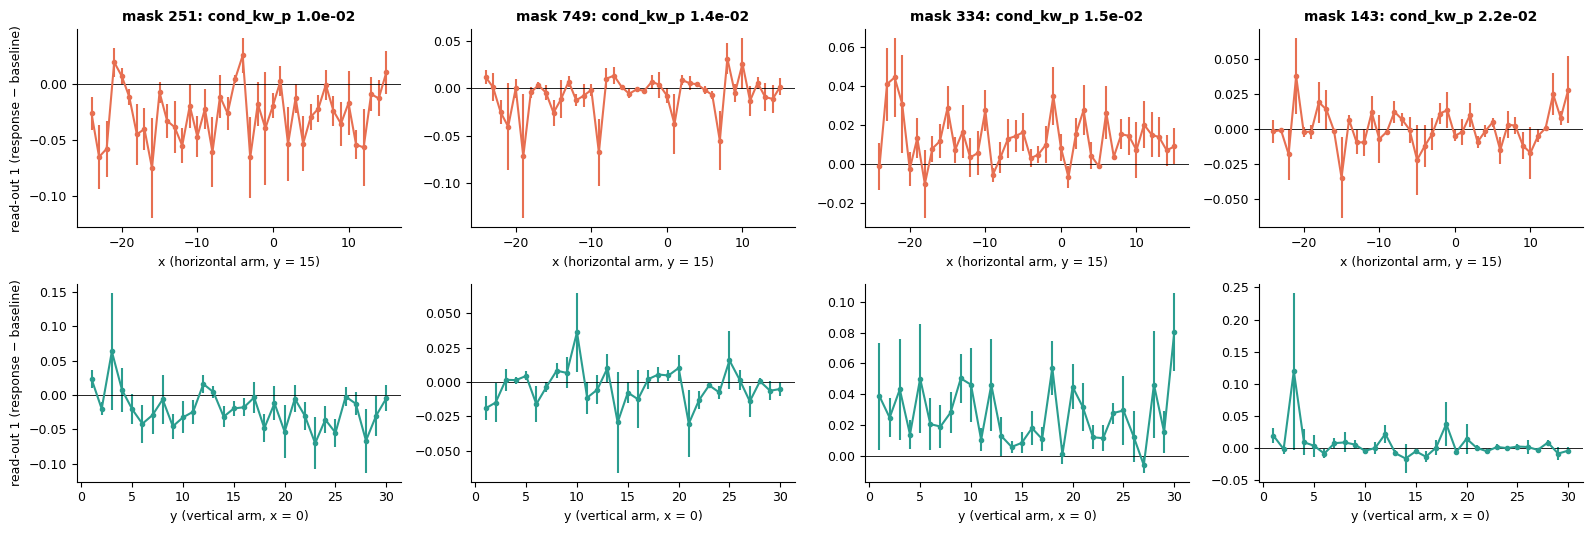

In [13]:
zr = (r.Zeta.Cell & RK & {"trace_source": "cascade25", "event_selector": "rf_checkerboard", "readout_idx": 1, "zeta_idx": 1} & "zeta_p < 0.001").proj()
rf = (r.Readout.Cell & zr & {"readout_idx": 1}).fetch("KEY", "cond_kw_p", order_by="cond_kw_p", limit=4, as_dict=True)
print(f"{RF}: {len(zr)} cells with zeta_p < 0.001 on read-out 1; the 4 with the strongest position dependence (cond_kw_p)")
if rf:
    c0 = (r.Readout.Condition & {k: v for k, v in rf[0].items() if k != "cond_kw_p"}).fetch("condition")
    xy0 = pd.Series(c0).str.split("|", expand=True).astype(float)
    Y0, X0 = xy0[1].mode()[0], xy0[0].mode()[0]
    odd = xy0[(xy0[1] != Y0) & (xy0[0] != X0)]
    npos = (r.Readout.Condition & {k: v for k, v in rf[0].items() if k != "cond_kw_p"}).fetch("n_onsets")
    print(f"presentations per position: median {np.median(npos):g} (min {npos.min()}, max {npos.max()})")
    print(f"horizontal arm at y = {Y0:g} ({int((xy0[1] == Y0).sum())} positions), vertical arm at x = {X0:g} ({int((xy0[0] == X0).sum())} positions)"
          + (f"; {len(odd)} label(s) on neither arm: {[f'{a:g}|{b:g}' for a, b in odd.values]}" if len(odd) else ""))
    fig, axs = plt.subplots(2, len(rf), figsize=(4 * len(rf), 5.4), squeeze=False)
    for j, row_ in enumerate(rf):
        kk = {k: v for k, v in row_.items() if k != "cond_kw_p"}
        c = (r.Readout.Condition & kk).fetch(format="frame").reset_index()
        xy = c.condition.str.split("|", expand=True).astype(float); c["x"], c["y"] = xy[0], xy[1]
        h, v = c[c.y == Y0].sort_values("x"), c[c.x == X0].sort_values("y")
        axs[0][j].errorbar(h.x, h.resp.astype(float), yerr=h.resp_sem.astype(float), fmt="o-", ms=3, color=COL["cascade25"])
        axs[1][j].errorbar(v.y, v.resp.astype(float), yerr=v.resp_sem.astype(float), fmt="o-", ms=3, color=COL["oasis"])
        for a_ in axs[:, j]: a_.axhline(0, color="k", lw=.6)
        axs[0][j].set(title=f"mask {kk['mask']}: cond_kw_p {row_['cond_kw_p']:.1e}", xlabel=f"x (horizontal arm, y = {Y0:g})")
        axs[1][j].set(xlabel=f"y (vertical arm, x = {X0:g})")
    axs[0][0].set_ylabel("read-out 1 (response − baseline)"); axs[1][0].set_ylabel("read-out 1 (response − baseline)")
    plt.tight_layout(); plt.show()

## 13. Across all sessions of the animal

`cells()` takes any restriction, so the same rule runs over every recording of the animal at once. Here the fraction of
responsive and reliable soma ROIs per grating recording, CASCADE and OASIS, in time.

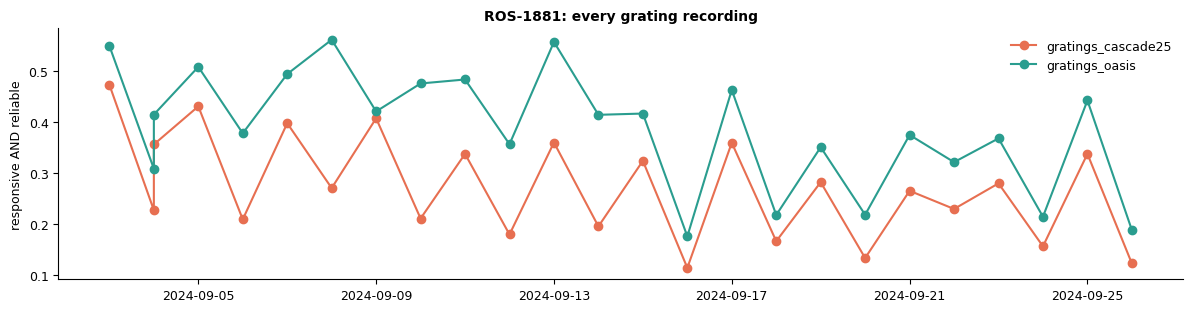

frac_good                                 n               
rule                    gratings_cascade25 gratings_oasis gratings_cascade25 gratings_oasis
day        scan_id                                                                         
2024-09-03 scan9FPY8W73              0.473          0.549              774.0          774.0
2024-09-04 scan9FPYUH9D              0.356          0.415              427.0          427.0
           scan9FPYV04U              0.227          0.308              480.0          480.0
2024-09-05 scan9FPZGABI              0.431          0.508              620.0          620.0
2024-09-06 scan9FQ014RK              0.209          0.378              397.0          397.0
2024-09-07 scan9FQ0MLVT              0.398          0.494              581.0          581.0
2024-09-08 scan9FQ18FWL              0.270          0.561              392.0          392.0
2024-09-09 scan9FQ1TN3R              0.407          0.421              523.0          523.0
2024-09-10 scan9FQ2FIRL              0.211          0.475              408.0          408.0
2024-09-11 scan9FQ30DXR              0.337          0.483              569.0          569.0

In [14]:
gscans = real[real.event_selector == "gratings"][["session_id", "scan_id", "day"]].drop_duplicates()
out = []
for rule in ("gratings_cascade25", "gratings_oasis"):
    ff = cells(rule, [{"session_id": s, "scan_id": c, "event_selector": "gratings"} for s, c in gscans[["session_id", "scan_id"]].values]).fetch(format="frame").reset_index()
    ff["good"] = ff.is_responsive.astype(bool) & ff.is_reliable.astype(bool)
    out.append(ff.groupby("scan_id").agg(n=("good", "size"), frac_good=("good", "mean")).assign(rule=rule).reset_index())
per = pd.concat(out).merge(gscans, on="scan_id").sort_values("day")
fig, ax = plt.subplots(figsize=(12, 3.2))
for rule, d in per.groupby("rule"):
    ax.plot(pd.to_datetime(d.day), d.frac_good, "o-", label=rule, color=COL["cascade25" if "cascade" in rule else "oasis"])
ax.set(ylabel="responsive AND reliable", title=f"{SUBJECT}: every grating recording"); ax.legend()
plt.tight_layout(); plt.show()
display(per.pivot_table(index=["day", "scan_id"], columns="rule", values=["n", "frac_good"]).round(3).head(10))

## 14. Are the tests honest? Random-onset controls

Each paradigm has a `*_random` selector: the same presentations moved to seeded random times. Nothing is time-locked
to them, so about 5 % of cells should pass p < 0.05. The same rule on the control is the false-positive rate of your
selection. Two things to know: the controls are computed for OASIS (one trace type is enough for calibration), and the
random onsets carry no condition labels, so reliability (`oracle_r`, which compares condition curves across repeats)
is not defined there; `is_reliable` is empty and only `is_responsive` is the calibration.

In [15]:
ctrl = []
for sel in ("gratings", "gratings_random"):
    for rule in ("gratings_cascade25", "gratings_oasis"):
        ff = cells(rule, [{"session_id": s, "scan_id": c, "event_selector": sel} for s, c in gscans[["session_id", "scan_id"]].values]).fetch("is_responsive", "is_reliable")
        if len(ff[0]):
            ctrl.append(dict(selector=sel, rule=rule, responsive=np.mean(ff[0].astype(bool)), reliable=np.mean(ff[1].astype(bool)),
                             both=np.mean(ff[0].astype(bool) & ff[1].astype(bool))))
display(pd.DataFrame(ctrl).round(3))

,selector,rule,responsive,reliable,both
0,gratings,gratings_cascade25,0.548,0.444,0.287
1,gratings,gratings_oasis,0.642,0.575,0.395
2,gratings_random,gratings_oasis,0.039,0.000,0.000


## 15. Recipes

```python
# in your own code (activates the module; writes only lookup contents, idempotently)
from adamacs.workers import responsiveness_worker as w
resp, imaging = w.activate("roselab_responsiveness")

# my animal's grating recordings
from adamacs.pipeline import session
mine = resp.ResponseTask & (session.Session & {"subject": "ROS-1881"}) & {"event_selector": "gratings"}

# good grating cells of those recordings (soma, ROI QC passed, responsive AND reliable)
good = resp.cells("gratings_cascade25", mine.proj()) & "is_responsive AND is_reliable"

# their read-out 16 values, ZETA and tuning
ro16 = resp.Readout.Cell & good.proj() & {"readout_idx": 16}
zeta = resp.Zeta.Cell & good.proj() & {"readout_idx": 16, "zeta_idx": 1}
tun  = resp.DirectionTuning.Cell & good.proj() & {"tuning_idx": 1}
df = (ro16 * zeta.proj("zeta_p") * tun.proj("gosi", "pref_ori", "hotelling_p")).fetch(format="frame")

# single trials of one cell, with their conditions
k = df.index[0]; key = dict(zip(df.index.names, k))
trials = (resp.Readout.Cell & key).fetch1("trial_resp")
labels = (resp.EventSet.Onset & key).fetch("condition", order_by="onset_idx")

# the read-out window you need is missing? stage it; the worker computes it
resp.plan_tasks(mine.proj(), trace_sources=["cascade25"], selectors=["gratings"], readouts=[16, 2], zetas=[(16, 1)],
                owner="me", tunings=[(16, 1)])
```

Rules of thumb:
* always restrict `event_selector` (and `readout_idx`), and subtract `imaging.RoiQC.Rejected`; `cells()` does both;
* make calls on CASCADE or OASIS; use dF/F0 for display;
* many grating cells respond to the stimulus **offset**: read-out 16 does not see that, ZETA on its epoch does;
* compare cells and sessions with effect sizes (`resp_auroc`, `fev`, `gosi_cv`), not with p-values.